# 02. Linear Regression for Multi-Company Next-Day Price Forecasting
### Integrated Project: AI-Based Intelligent Trading System — Assignment 2

---

## 1. Title and Objective

### Understanding Regression in Quantitative Trading
**Regression** is a foundational branch of supervised machine learning designed to model continuous numerical targets from explanatory features. In ordinary linear regression, the model estimates a weight vector $\boldsymbol{\beta}$ and intercept $\beta_0$ by minimizing the Residual Sum of Squares (RSS):
$$y = \beta_0 + \sum_{j=1}^{p} \beta_j X_j + \epsilon$$

### Next-Day Price Forecasting Problem Definition
In financial market analysis, temporal causality is paramount. We predict the **next trading day's closing price** ($Close_{t+1}$) using information available up to market close on the current day ($X_t$):
$$\text{Today's Market Features } (X_t) \longrightarrow \text{Predict } \longrightarrow \text{Tomorrow's Close } (Close_{t+1})$$

- **Target Definition**: $\text{Target\_Next\_Close}_t = Close_{t+1} = \text{Close.shift(-1)}$
- **Strict No-Lookahead Guarantee**: Target shift is performed **strictly within each company** (`groupby('Ticker')`), ensuring company boundaries and future prices never contaminate training features.

### Multi-Company Scope: 10 Separate Models
Rather than pooling companies with wildly differing nominal price levels (e.g. NVDA split-adjusted low of \$3.29 vs. META high of \$632.68) into a single naive regression, we train **10 independent linear regression models**:
- `AAPL` (Apple), `MSFT` (Microsoft), `GOOGL` (Alphabet), `AMZN` (Amazon), `NVDA` (NVIDIA)
- `META` (Meta Platforms), `TSLA` (Tesla), `JPM` (JPMorgan Chase), `V` (Visa), `JNJ` (Johnson & Johnson)

### Assignment 2 Educational Workflow:
1. Title / Objective
2. Imports
3. Dataset Loading
4. Target Creation (independent shift per ticker)
5. Feature Selection
6. Chronological Train/Test Split (80/20 per ticker)
7. Scaling (StandardScaler fitted strictly on training data)
8. Model Training (10 OLS models)
9. Predictions
10. Evaluation (MAE, MSE, RMSE, R²)
11. Residual Analysis
12. Visualizations
13. Feature Importance & Multicollinearity
14. Critical Financial Limitations (High R² vs Trading Profitability)
15. Exports & Quality Checks
16. Conclusion


---

## 2. Import Libraries
We import scientific computing, visualization, and modeling libraries (`scikit-learn` linear models, scalers, and metrics).


In [1]:
import os
import sys
from pathlib import Path

# Ensure project root is in the Python path
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "AI-Intelligent-Trading-System" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# Configure plotting aesthetics
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
sns.set_palette("muted")

print(f"Project Root: {PROJECT_ROOT}")
print("Libraries imported successfully!")


Project Root: C:\Users\pushk\OneDrive\Desktop\Pushkar\AI-Intelligent-Trading-System
Libraries imported successfully!


---

## 3. Dataset Loading
We load the verified multi-company engineered feature dataset generated in Assignment 1 (`data/processed/multi_company_features.csv`). It contains 15,010 clean trading sessions across all 10 companies from **2019-01-15** through **2024-12-31**.


In [2]:
features_path = PROJECT_ROOT / "data" / "processed" / "multi_company_features.csv"
df_features = pd.read_csv(features_path)
df_features["Date"] = pd.to_datetime(df_features["Date"])
df_features = df_features.sort_values(by=["Ticker", "Date"]).reset_index(drop=True)

EXPECTED_TICKERS = sorted(["AAPL", "MSFT", "GOOGL", "AMZN", "NVDA", "META", "TSLA", "JPM", "V", "JNJ"])
COMPANY_NAMES = {
    "AAPL": "Apple", "MSFT": "Microsoft", "GOOGL": "Alphabet", "AMZN": "Amazon",
    "NVDA": "NVIDIA", "META": "Meta Platforms", "TSLA": "Tesla", "JPM": "JPMorgan Chase",
    "V": "Visa", "JNJ": "Johnson & Johnson"
}

print(f"Loaded Feature Dataset: {df_features.shape[0]:,} rows, {df_features.shape[1]} columns")
print(f"Date Range:             {df_features['Date'].min().strftime('%Y-%m-%d')} to {df_features['Date'].max().strftime('%Y-%m-%d')}")
print(f"Unique Tickers ({df_features['Ticker'].nunique()}):      {EXPECTED_TICKERS}\n")

display(df_features.head(3))


Loaded Feature Dataset: 15,010 rows, 15 columns
Date Range:             2019-01-15 to 2024-12-31
Unique Tickers (10):      ['AAPL', 'AMZN', 'GOOGL', 'JNJ', 'JPM', 'META', 'MSFT', 'NVDA', 'TSLA', 'V']



,Date,Ticker,Open,High,Low,Close,Volume,Daily_Return,Price_Range,Candle_Body,Upper_Shadow,Lower_Shadow,SMA_5,SMA_10,Volatility_5
0,2019-01-15,AAPL,37.567501,38.347500,37.512501,38.267502,114843600,0.020467,0.834999,0.700001,0.079998,0.055000,38.1235,37.73800,0.015733
1,2019-01-16,AAPL,38.270000,38.970001,38.250000,38.735001,122278800,0.012217,0.720001,0.465000,0.235001,0.020000,38.2050,37.66350,0.014803
2,2019-01-17,AAPL,38.549999,39.415001,38.314999,38.965000,119284800,0.005938,1.100002,0.415001,0.450001,0.235001,38.3080,38.00525,0.014900


---

## 4. Target Creation (Next-Day Close)
We compute the forward-looking regression target:
$$\text{Target\_Next\_Close}_t = Close_{t+1} = \text{Close.shift(-1)}$$

### Strict Multi-Company Requirement: Groupby Ticker Shift
The target shift **MUST** be performed within each `Ticker` group. Global shifting would cause company A's final trading session to adopt company B's first session as its next-day close.

The final observation for each company (`2024-12-31`) has no subsequent trading session in the historical dataset, producing exactly 1 NaN per ticker. We drop these 10 final rows, leaving **15,000 usable regression observations** (exactly 1,500 per company).


In [3]:
# Create target independently within each Ticker group
df_features["Target_Next_Close"] = df_features.groupby("Ticker")["Close"].shift(-1)

# Verify that exactly 10 NaNs were created (one for the last row of each ticker)
nan_counts = df_features["Target_Next_Close"].isnull().sum()
print(f"Target NaNs created across dataset: {nan_counts} (expected 10)")
assert nan_counts == 10, f"Expected 10 target NaNs, found {nan_counts}"

# Remove the final row of each company
df_reg = df_features.dropna(subset=["Target_Next_Close"]).reset_index(drop=True)

# Verify clean regression dataset shape
total_usable = len(df_reg)
print(f"Total Usable Observations:          {total_usable:,} (expected 15,000)")
assert total_usable == 15000, f"Expected 15,000 observations, got {total_usable}"

# Check count per ticker
ticker_counts = df_reg["Ticker"].value_counts().to_dict()
assert all(cnt == 1500 for cnt in ticker_counts.values()), "Not all tickers have 1,500 observations!"

print("Rows per company (exactly 1,500 each):")
display(pd.DataFrame(list(ticker_counts.items()), columns=["Ticker", "Usable Rows"]))


Target NaNs created across dataset: 10 (expected 10)
Total Usable Observations:          15,000 (expected 15,000)
Rows per company (exactly 1,500 each):


,Ticker,Usable Rows
0,AAPL,1500
1,AMZN,1500
2,GOOGL,1500
3,JNJ,1500
4,JPM,1500
5,META,1500
6,MSFT,1500
7,NVDA,1500
8,TSLA,1500
9,V,1500


---

## 5. Feature Selection
We select the 13 numerical market and engineered technical features computed on day $t$ to predict the day $t+1$ closing price.

### Features Used ($X_t$):
1. **Raw Market Features**: `Open`, `High`, `Low`, `Close`, `Volume`
2. **Intraday Geometries**: `Price_Range`, `Candle_Body`, `Upper_Shadow`, `Lower_Shadow`
3. **Moving Averages & Momentum**: `Daily_Return`, `SMA_5`, `SMA_10`
4. **Volatility**: `Volatility_5`

> **Excluded from Model Features**: `Date`, `Ticker`, and `Target_Next_Close`. `Date` and `Ticker` are preserved for indexing and multi-asset tracking, but never passed as numerical inputs to OLS.


In [4]:
feature_cols = [
    "Open", "High", "Low", "Close", "Volume",
    "Daily_Return", "Price_Range", "Candle_Body",
    "Upper_Shadow", "Lower_Shadow", "SMA_5", "SMA_10", "Volatility_5"
]

print(f"Selected Explanatory Features ({len(feature_cols)}):\n{feature_cols}\n")
print(f"Target Column: Target_Next_Close")
print(f"Metadata Tracking Columns: ['Date', 'Ticker']")


Selected Explanatory Features (13):
['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'Price_Range', 'Candle_Body', 'Upper_Shadow', 'Lower_Shadow', 'SMA_5', 'SMA_10', 'Volatility_5']

Target Column: Target_Next_Close
Metadata Tracking Columns: ['Date', 'Ticker']


---

## 6. Chronological Train / Test Split (80% / 20%)
In time-series financial modeling, **shuffling or random k-fold splitting is strictly prohibited** because it leaks future information into past training bars.

We implement a strict **chronological 80/20 train/test split within each company**:
- **Training Set (First 80%)**: 1,200 observations per company (12,000 observations total)
- **Testing Set (Last 20%)**: 300 observations per company (3,000 observations total)
- **Time Horizon**: Training runs from `2019-01-15` to `2023-10-19`; Testing evaluates out-of-sample performance from `2023-10-20` to `2024-12-30`.


In [5]:
train_dfs = []
test_dfs = []
split_summary = []

TRAIN_RATIO = 0.80

for ticker in EXPECTED_TICKERS:
    grp = df_reg[df_reg["Ticker"] == ticker].sort_values("Date").reset_index(drop=True)
    n_total = len(grp)
    n_train = int(n_total * TRAIN_RATIO)  # 1,200
    n_test = n_total - n_train            # 300
    
    tr_sub = grp.iloc[:n_train].copy()
    te_sub = grp.iloc[n_train:].copy()
    
    train_dfs.append(tr_sub)
    test_dfs.append(te_sub)
    
    split_summary.append({
        "Ticker": ticker,
        "Company": COMPANY_NAMES[ticker],
        "Train Rows": len(tr_sub),
        "Test Rows": len(te_sub),
        "Train Start": tr_sub["Date"].min().strftime("%Y-%m-%d"),
        "Train End": tr_sub["Date"].max().strftime("%Y-%m-%d"),
        "Test Start": te_sub["Date"].min().strftime("%Y-%m-%d"),
        "Test End": te_sub["Date"].max().strftime("%Y-%m-%d")
    })

df_train_all = pd.concat(train_dfs, ignore_index=True)
df_test_all = pd.concat(test_dfs, ignore_index=True)
df_split_summary = pd.DataFrame(split_summary)

print("=== Chronological Train / Test Split Summary ===")
print(f"Total Training Observations: {len(df_train_all):,} (12,000 expected)")
print(f"Total Testing Observations:  {len(df_test_all):,} (3,000 expected)\n")
display(df_split_summary)


=== Chronological Train / Test Split Summary ===
Total Training Observations: 12,000 (12,000 expected)
Total Testing Observations:  3,000 (3,000 expected)



,Ticker,Company,Train Rows,Test Rows,Train Start,Train End,Test Start,Test End
0,AAPL,Apple,1200,300,2019-01-15,2023-10-19,2023-10-20,2024-12-30
1,AMZN,Amazon,1200,300,2019-01-15,2023-10-19,2023-10-20,2024-12-30
2,GOOGL,Alphabet,1200,300,2019-01-15,2023-10-19,2023-10-20,2024-12-30
3,JNJ,Johnson & Johnson,1200,300,2019-01-15,2023-10-19,2023-10-20,2024-12-30
4,JPM,JPMorgan Chase,1200,300,2019-01-15,2023-10-19,2023-10-20,2024-12-30
5,META,Meta Platforms,1200,300,2019-01-15,2023-10-19,2023-10-20,2024-12-30
6,MSFT,Microsoft,1200,300,2019-01-15,2023-10-19,2023-10-20,2024-12-30
7,NVDA,NVIDIA,1200,300,2019-01-15,2023-10-19,2023-10-20,2024-12-30
8,TSLA,Tesla,1200,300,2019-01-15,2023-10-19,2023-10-20,2024-12-30
9,V,Visa,1200,300,2019-01-15,2023-10-19,2023-10-20,2024-12-30


---

## 7. Feature Scaling (StandardScaler)
Features span completely different physical scales (e.g., `Volume` in hundreds of millions vs. `Daily_Return` in small decimals).

> **Crucial Anti-Leakage Rule**: `StandardScaler` is fitted **ONLY on the training set** for each company (`scaler.fit(X_train)`). The test set is strictly transformed using the parameters (mean and standard deviation) learned from the training data (`scaler.transform(X_test)`). The scaler is **NEVER** fit on the complete or testing dataset.


---

## 8. Linear Regression Model Training & Prediction
We train **10 independent Linear Regression models** using Ordinary Least Squares (OLS). Each model learns the specific price level dynamics and volatility characteristics of its respective company.


In [6]:
models = {}
scalers = {}
eval_metrics = []
test_predictions_list = []

for ticker in EXPECTED_TICKERS:
    tr_sub = df_train_all[df_train_all["Ticker"] == ticker].sort_values("Date").reset_index(drop=True)
    te_sub = df_test_all[df_test_all["Ticker"] == ticker].sort_values("Date").reset_index(drop=True)
    
    X_train = tr_sub[feature_cols].values
    y_train = tr_sub["Target_Next_Close"].values
    X_test = te_sub[feature_cols].values
    y_test = te_sub["Target_Next_Close"].values
    
    # 1. Fit scaler strictly on training set
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    scalers[ticker] = scaler
    
    # 2. Fit Linear Regression OLS model
    model = LinearRegression()
    model.fit(X_train_scaled, y_train)
    models[ticker] = model
    
    # 3. Generate predictions
    y_pred_train = model.predict(X_train_scaled)
    y_pred_test = model.predict(X_test_scaled)
    
    # 4. Compute metrics
    tr_mae = mean_absolute_error(y_train, y_pred_train)
    te_mae = mean_absolute_error(y_test, y_pred_test)
    tr_mse = mean_squared_error(y_train, y_pred_train)
    te_mse = mean_squared_error(y_test, y_pred_test)
    tr_rmse = np.sqrt(tr_mse)
    te_rmse = np.sqrt(te_mse)
    tr_r2 = r2_score(y_train, y_pred_train)
    te_r2 = r2_score(y_test, y_pred_test)
    
    eval_metrics.append({
        "Ticker": ticker,
        "Company": COMPANY_NAMES[ticker],
        "Train_Rows": len(tr_sub),
        "Test_Rows": len(te_sub),
        "Train_Start": tr_sub["Date"].min().strftime("%Y-%m-%d"),
        "Train_End": tr_sub["Date"].max().strftime("%Y-%m-%d"),
        "Test_Start": te_sub["Date"].min().strftime("%Y-%m-%d"),
        "Test_End": te_sub["Date"].max().strftime("%Y-%m-%d"),
        "Train_MAE": round(tr_mae, 4),
        "Test_MAE": round(te_mae, 4),
        "Train_MSE": round(tr_mse, 4),
        "Test_MSE": round(te_mse, 4),
        "Train_RMSE": round(tr_rmse, 4),
        "Test_RMSE": round(te_rmse, 4),
        "Train_R2": round(tr_r2, 4),
        "Test_R2": round(te_r2, 4)
    })
    
    # 5. Store test prediction records with Residual
    pred_records = pd.DataFrame({
        "Date": te_sub["Date"].dt.strftime("%Y-%m-%d"),
        "Ticker": ticker,
        "Actual_Next_Close": np.round(y_test, 4),
        "Predicted_Next_Close": np.round(y_pred_test, 4),
        "Residual": np.round(y_test - y_pred_test, 4)
    })
    test_predictions_list.append(pred_records)

df_regression_summary = pd.DataFrame(eval_metrics)
df_multi_predictions = pd.concat(test_predictions_list, ignore_index=True)

print("Training completed for all 10 companies successfully!")
print(f"Combined Out-of-Sample Predictions: {len(df_multi_predictions):,} rows across {df_multi_predictions['Ticker'].nunique()} companies")


Training completed for all 10 companies successfully!
Combined Out-of-Sample Predictions: 3,000 rows across 10 companies


---

## 9. Model Evaluation Metrics
We evaluate each model using standard regression error metrics:
- **Mean Absolute Error (MAE)**: $\frac{1}{n} \sum |y - \hat{y}|$ (average dollar magnitude of forecast deviation)
- **Mean Squared Error (MSE)**: $\frac{1}{n} \sum (y - \hat{y})^2$
- **Root Mean Squared Error (RMSE)**: $\sqrt{\text{MSE}}$ (penalizes large outlier forecast errors)
- **Coefficient of Determination ($R^2$)**: $1 - \frac{\sum (y - \hat{y})^2}{\sum (y - \bar{y})^2}$ (proportion of target variance explained)


In [7]:
display_cols = ["Ticker", "Company", "Train_RMSE", "Test_RMSE", "Train_MAE", "Test_MAE", "Train_R2", "Test_R2"]
print("=== Multi-Company Regression Performance Comparison ===")
display(df_regression_summary[display_cols])


=== Multi-Company Regression Performance Comparison ===


,Ticker,Company,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_R2,Test_R2
0,AAPL,Apple,2.3694,2.8243,1.6916,2.0736,0.9972,0.9869
1,AMZN,Amazon,2.8132,3.1767,1.9953,2.3656,0.9920,0.9794
2,GOOGL,Alphabet,1.9158,2.9148,1.3566,2.0293,0.9957,0.9739
3,JNJ,Johnson & Johnson,1.8134,1.5351,1.2827,1.1530,0.9854,0.9400
4,JPM,JPMorgan Chase,2.3043,3.0610,1.6531,2.0149,0.9888,0.9876
5,META,Meta Platforms,6.0574,10.4185,4.0396,7.0439,0.9920,0.9858
6,MSFT,Microsoft,4.3225,5.2482,3.0972,3.9571,0.9960,0.9613
7,NVDA,NVIDIA,0.6399,3.2520,0.4015,2.3469,0.9967,0.9905
8,TSLA,Tesla,7.6844,9.3897,4.9278,6.4500,0.9951,0.9793
9,V,Visa,3.3756,3.0108,2.3913,2.2630,0.9822,0.9737


### Objective Evaluation Observations:
1. **Scale-Dependent Dollar Metrics**:
   - Dollar-denominated errors (MAE and RMSE) directly scale with absolute share price. Companies trading at lower price ranges like **NVDA** (split-adjusted, Test MAE: \$2.35) and **JNJ** (Test MAE: \$1.15) naturally exhibit lower absolute dollar errors than high-priced stocks like **META** (trading \$300-\$630, Test MAE: \$7.04) and **TSLA** (Test MAE: \$6.45).
   - Therefore, comparing dollar RMSE directly across different assets without considering share price scale is methodologically flawed.
2. **Consistent High $R^2$ Across All 10 Companies**:
   - Out-of-sample $R^2$ exceeds **0.94** for every single company (ranging from **0.9400 for JNJ** to **0.9905 for NVDA**).
   - In the training set, $R^2$ ranges from **0.9822 to 0.9972**.
3. **Train vs. Test Generalization**:
   - Test RMSE is close to Train RMSE across all 10 companies, demonstrating good out-of-sample generalization without extreme overfitting.


---

## 10. Residual Analysis
The model residual is the difference between actual and predicted next-day close:
$$\text{Residual} = \text{Actual\_Next\_Close} - \text{Predicted\_Next\_Close}$$

In a well-specified regression model, residuals should be roughly centered at zero, symmetrically distributed, and show no structural trends over time.


C:\Users\pushk\AppData\Local\Temp\ipykernel_3516\417015420.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_multi_predictions, x="Ticker", y="Residual", ax=axes[0, 1], palette="muted", order=EXPECTED_TICKERS)


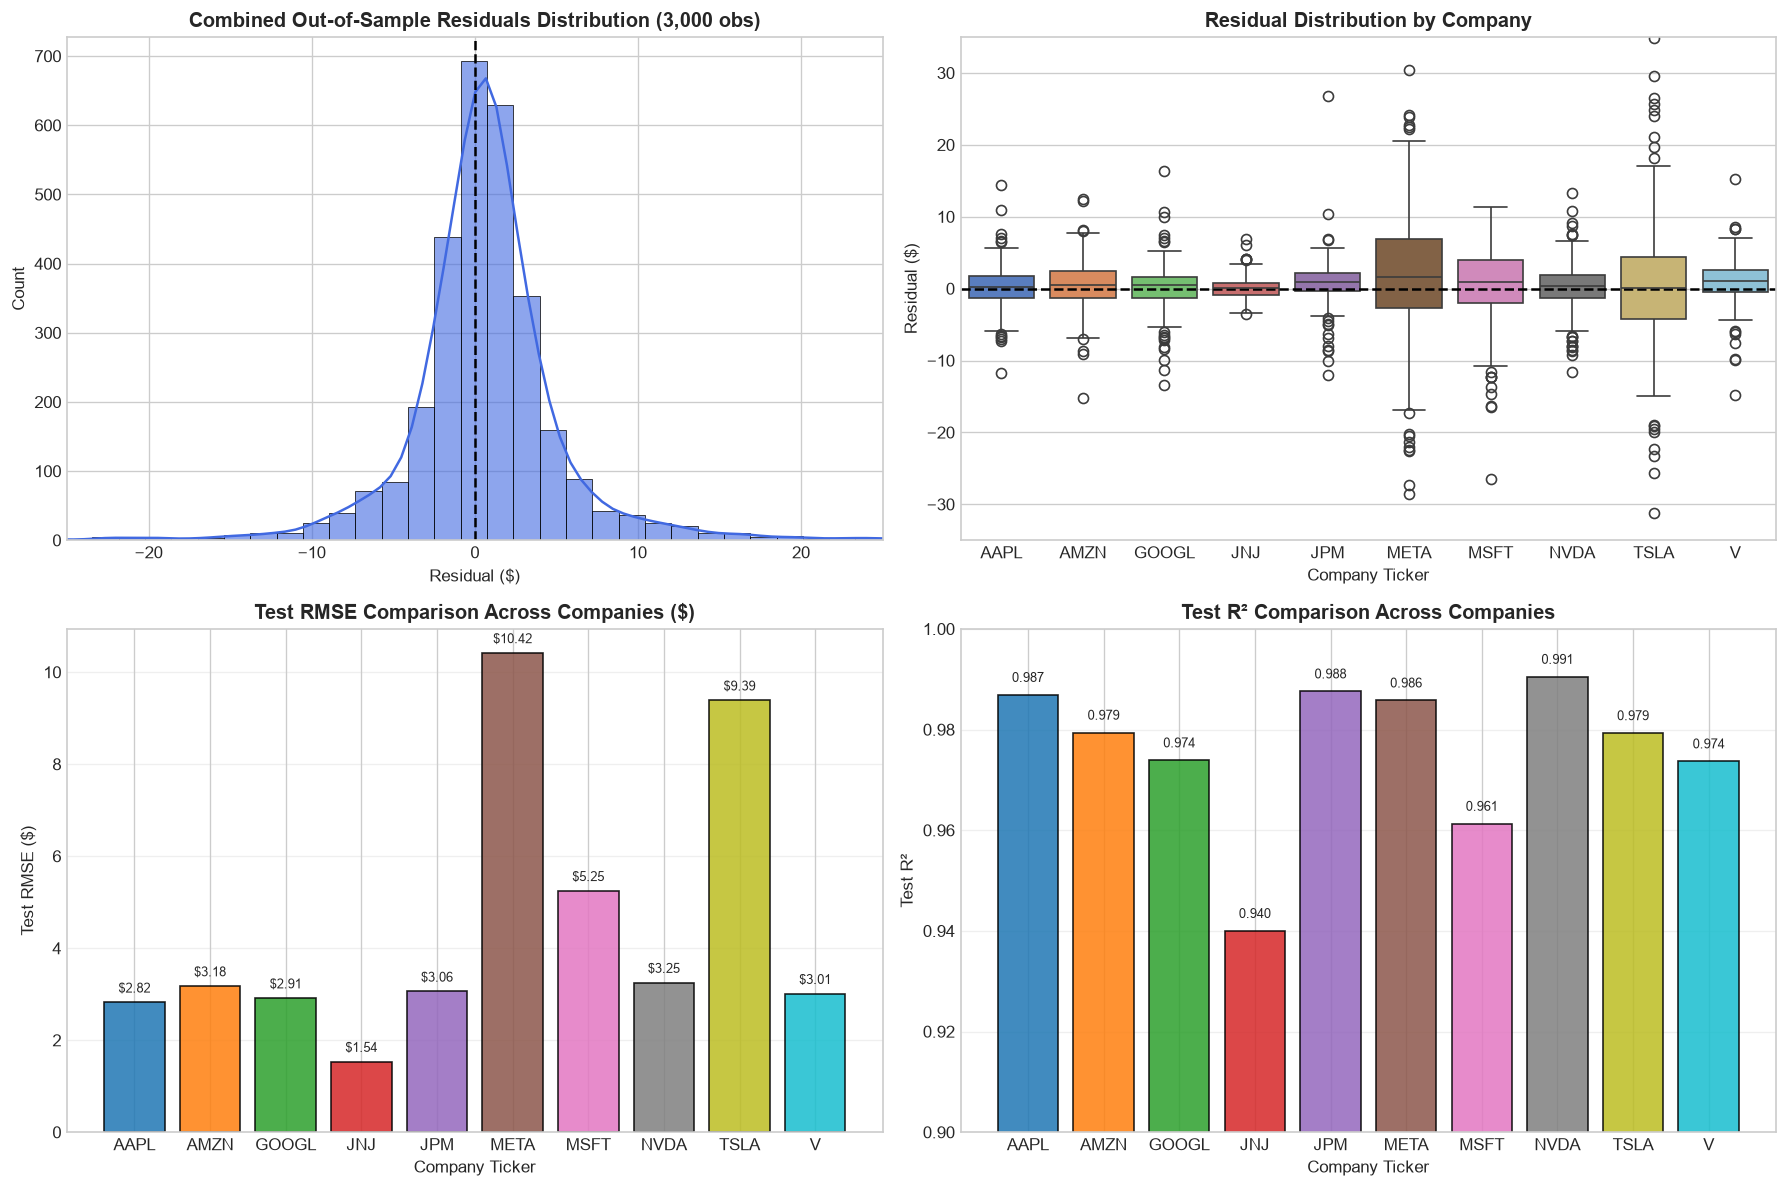

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Residuals Distribution (All 10 Companies Combined)
sns.histplot(df_multi_predictions["Residual"], bins=80, kde=True, ax=axes[0, 0], color="royalblue", alpha=0.6)
axes[0, 0].axvline(0, color="black", linestyle="--", linewidth=1.5)
axes[0, 0].set_title("Combined Out-of-Sample Residuals Distribution (3,000 obs)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Residual ($)")
axes[0, 0].set_xlim(-25, 25)

# 2. Residual Boxplots by Company
sns.boxplot(data=df_multi_predictions, x="Ticker", y="Residual", ax=axes[0, 1], palette="muted", order=EXPECTED_TICKERS)
axes[0, 1].axhline(0, color="black", linestyle="--", linewidth=1.5)
axes[0, 1].set_title("Residual Distribution by Company", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Company Ticker")
axes[0, 1].set_ylabel("Residual ($)")
axes[0, 1].set_ylim(-35, 35)

# 3. Test RMSE Comparison Across Companies
palette = sns.color_palette("tab10", n_colors=10)
bars_rmse = axes[1, 0].bar(df_regression_summary["Ticker"], df_regression_summary["Test_RMSE"], color=palette, edgecolor="black", alpha=0.85)
axes[1, 0].set_title("Test RMSE Comparison Across Companies ($)", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Company Ticker")
axes[1, 0].set_ylabel("Test RMSE ($)")
axes[1, 0].grid(True, alpha=0.3, axis="y")
for b in bars_rmse:
    h = b.get_height()
    axes[1, 0].text(b.get_x() + b.get_width() / 2, h + 0.15, f"${h:.2f}", ha="center", va="bottom", fontsize=8)

# 4. Test R2 Comparison Across Companies
bars_r2 = axes[1, 1].bar(df_regression_summary["Ticker"], df_regression_summary["Test_R2"], color=palette, edgecolor="black", alpha=0.85)
axes[1, 1].set_title("Test R² Comparison Across Companies", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Company Ticker")
axes[1, 1].set_ylabel("Test R²")
axes[1, 1].set_ylim(0.90, 1.0)
axes[1, 1].grid(True, alpha=0.3, axis="y")
for b in bars_r2:
    h = b.get_height()
    axes[1, 1].text(b.get_x() + b.get_width() / 2, h + 0.002, f"{h:.3f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()


---

## 11. Actual vs. Predicted Price Trajectories (10 Separate Panels)
Because each stock trades on a vastly different nominal price scale, displaying all stocks on a single y-axis creates severe visual distortion. We display **10 individual subplots**, each with independent axes to inspect forecast alignment over the test window (`2023-10-20` to `2024-12-30`).


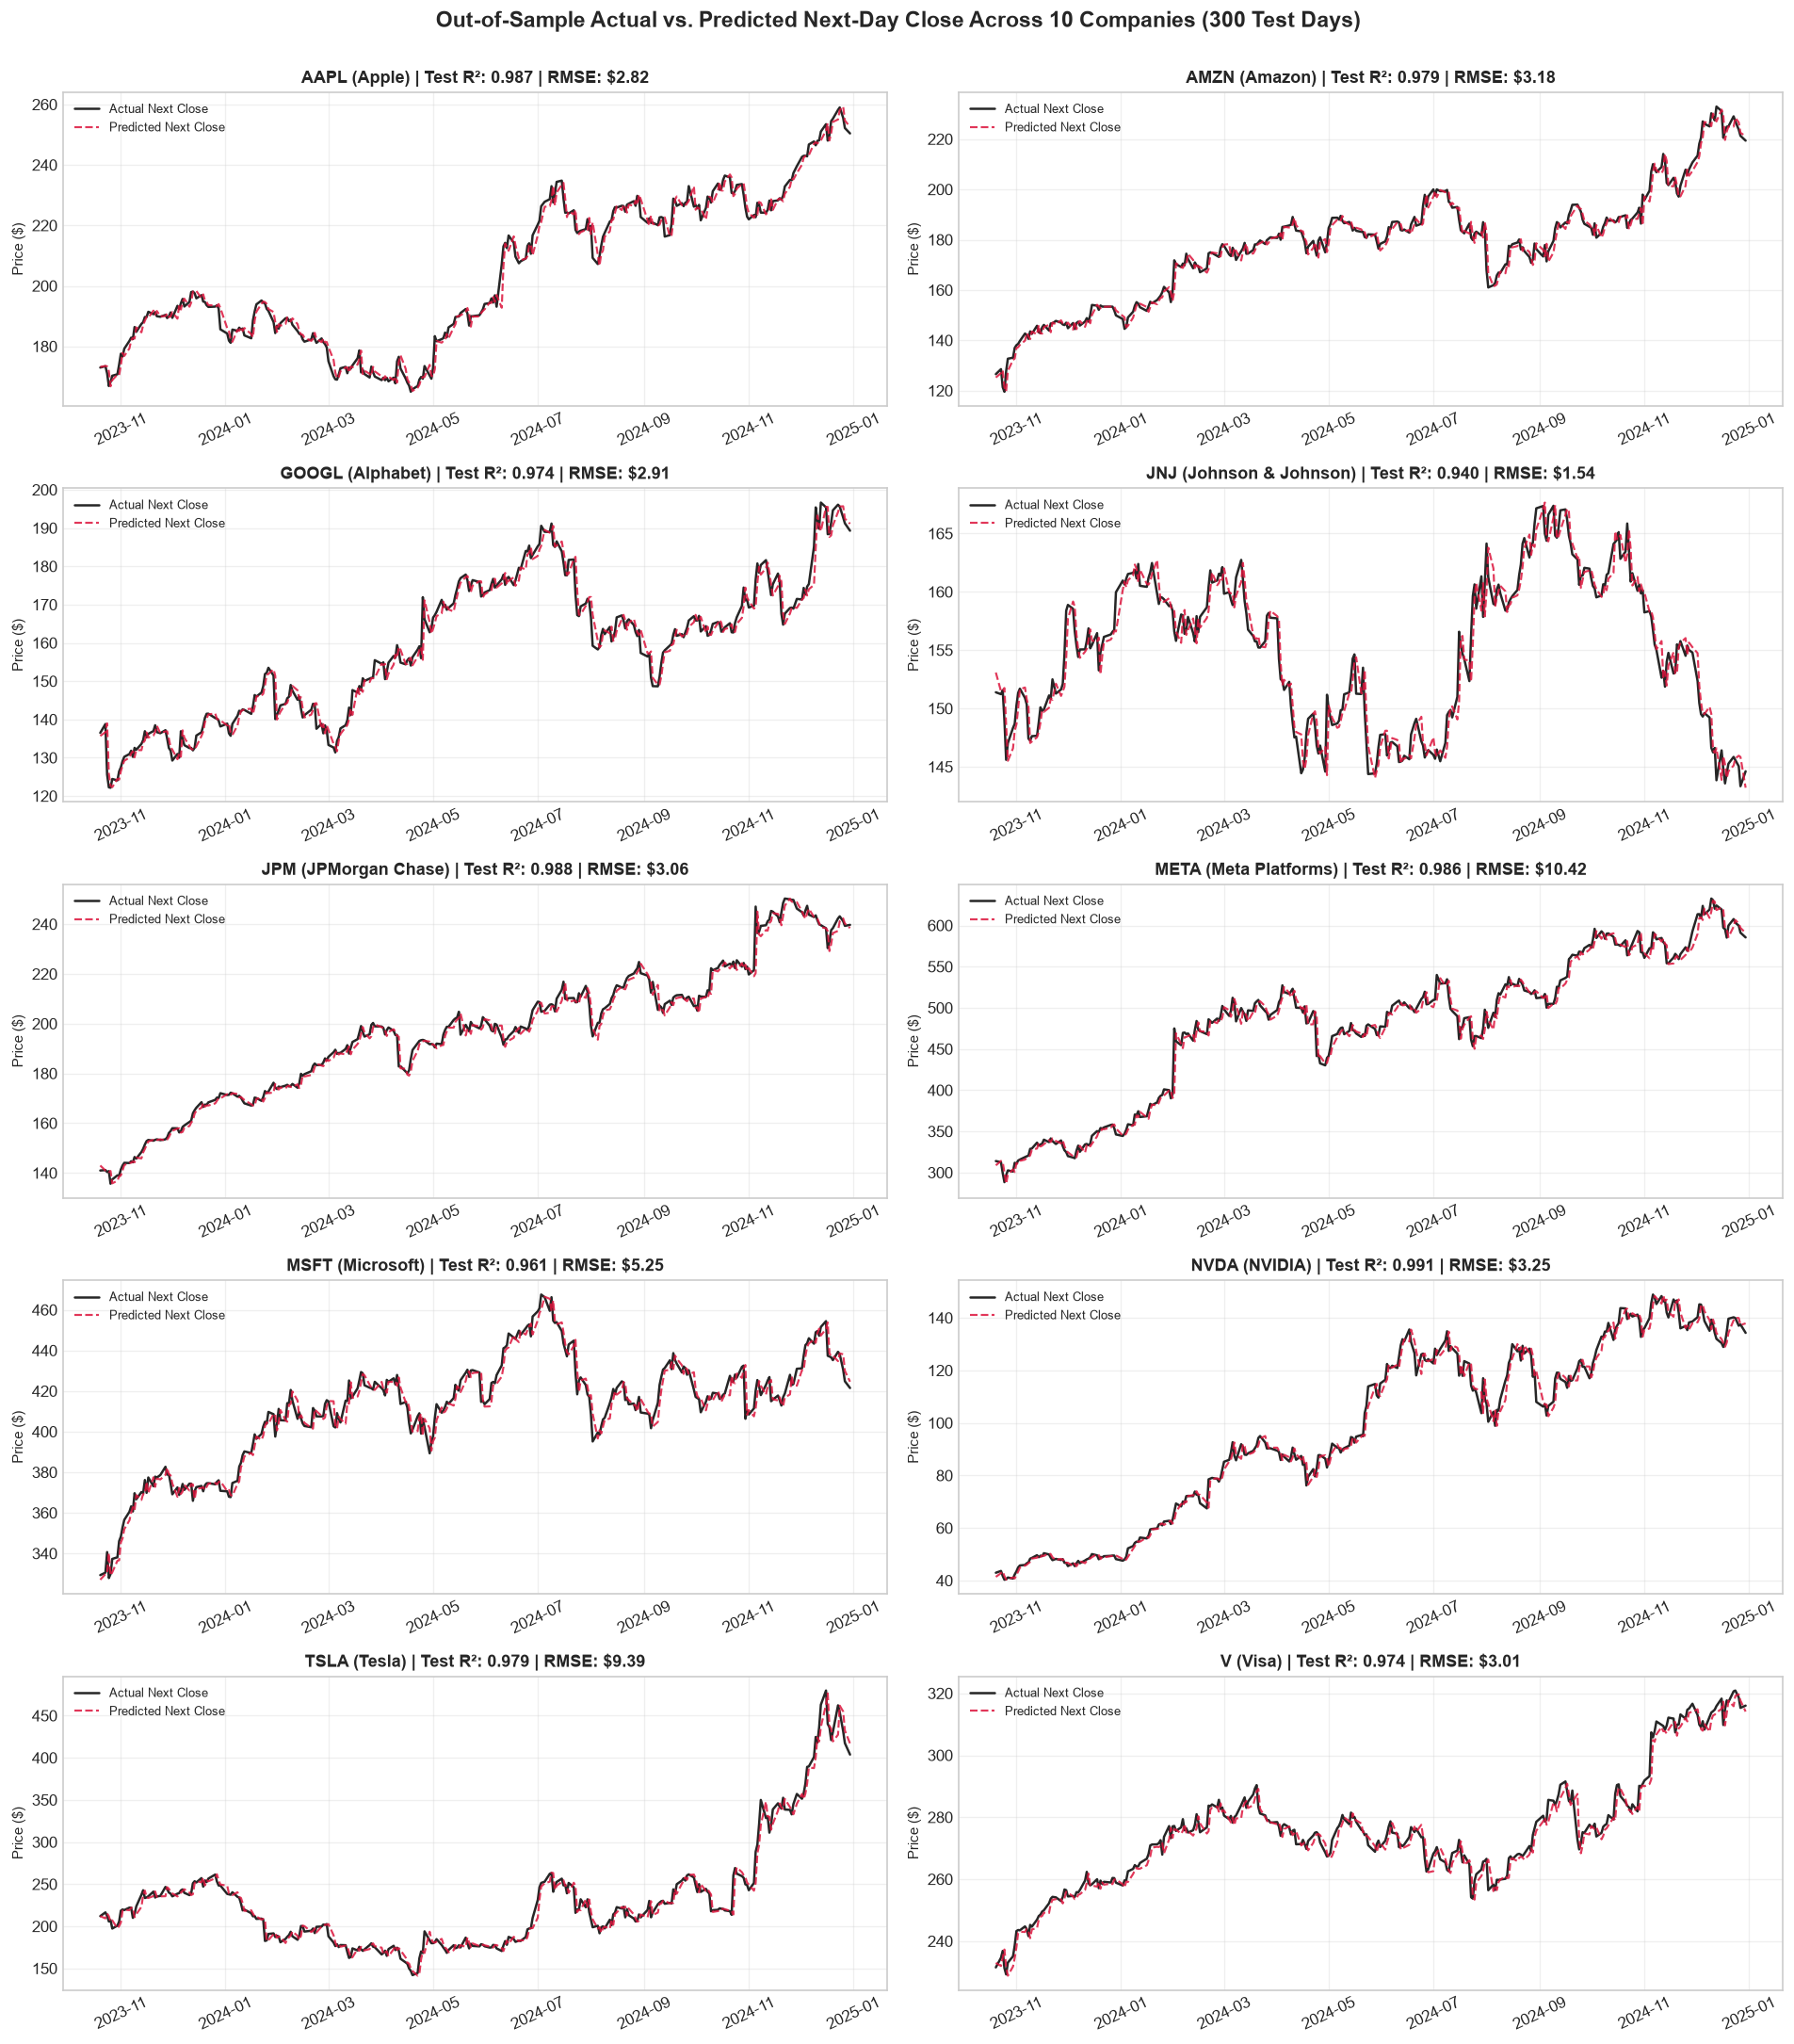

In [9]:
fig, axes = plt.subplots(5, 2, figsize=(16, 18), sharex=False)
axes = axes.flatten()

for idx, ticker in enumerate(EXPECTED_TICKERS):
    sub = df_multi_predictions[df_multi_predictions["Ticker"] == ticker].copy()
    sub["Date"] = pd.to_datetime(sub["Date"])
    ax = axes[idx]
    
    ax.plot(sub["Date"], sub["Actual_Next_Close"], label="Actual Next Close", color="black", linewidth=1.5, alpha=0.85)
    ax.plot(sub["Date"], sub["Predicted_Next_Close"], label="Predicted Next Close", color="crimson", linestyle="--", linewidth=1.3, alpha=0.85)
    
    r2_val = df_regression_summary[df_regression_summary["Ticker"] == ticker]["Test_R2"].values[0]
    rmse_val = df_regression_summary[df_regression_summary["Ticker"] == ticker]["Test_RMSE"].values[0]
    
    ax.set_title(f"{ticker} ({COMPANY_NAMES[ticker]}) | Test R²: {r2_val:.3f} | RMSE: ${rmse_val:.2f}", fontsize=11, fontweight="bold")
    ax.set_ylabel("Price ($)", fontsize=9)
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=25)

plt.suptitle("Out-of-Sample Actual vs. Predicted Next-Day Close Across 10 Companies (300 Test Days)", fontsize=14, fontweight="bold", y=1.002)
plt.tight_layout()
plt.show()


---

## 12. Regression Coefficients & Feature Multicollinearity
We inspect the learned OLS regression coefficients for each company across the standardized feature set.


=== OLS Standardized Coefficients Across 10 Companies ===


,Ticker,Open,High,Low,Close,Volume,Daily_Return,Price_Range,Candle_Body,Upper_Shadow,Lower_Shadow,SMA_5,SMA_10,Volatility_5
0,AAPL,10.891,10.805,11.031,10.941,0.278,-0.249,-0.202,1.203,0.037,-0.048,-0.227,1.803,-0.259
1,AMZN,7.691,7.665,7.838,7.806,0.021,-0.166,-0.022,1.286,0.054,-0.108,-0.207,0.596,-0.052
2,GOOGL,7.323,7.265,7.428,7.368,0.131,-0.066,-0.150,0.697,0.094,0.195,-2.813,2.634,-0.160
3,JNJ,3.789,3.827,3.835,3.881,-0.084,-0.378,-0.081,0.980,0.224,0.298,-0.651,0.185,-0.030
4,JPM,5.918,5.950,5.951,5.987,-0.024,-0.408,0.024,0.894,-0.018,0.184,-2.608,0.313,-0.264
5,META,16.548,16.475,16.778,16.686,-0.012,-0.041,-0.224,1.950,-0.061,-0.022,-4.183,5.359,-0.286
6,MSFT,16.748,16.632,16.964,16.836,0.256,-0.344,0.024,1.592,-0.027,-0.093,-1.363,2.289,-0.291
7,NVDA,2.653,2.612,2.711,2.667,0.003,0.001,0.004,0.248,-0.026,0.062,1.231,-0.695,-0.014
8,TSLA,27.111,26.619,27.868,27.325,-0.022,0.065,0.206,2.894,-0.930,-0.123,5.886,-5.441,0.081
9,V,6.720,6.785,6.802,6.881,0.206,-0.594,0.040,1.491,-0.048,0.039,-4.439,2.366,-0.295


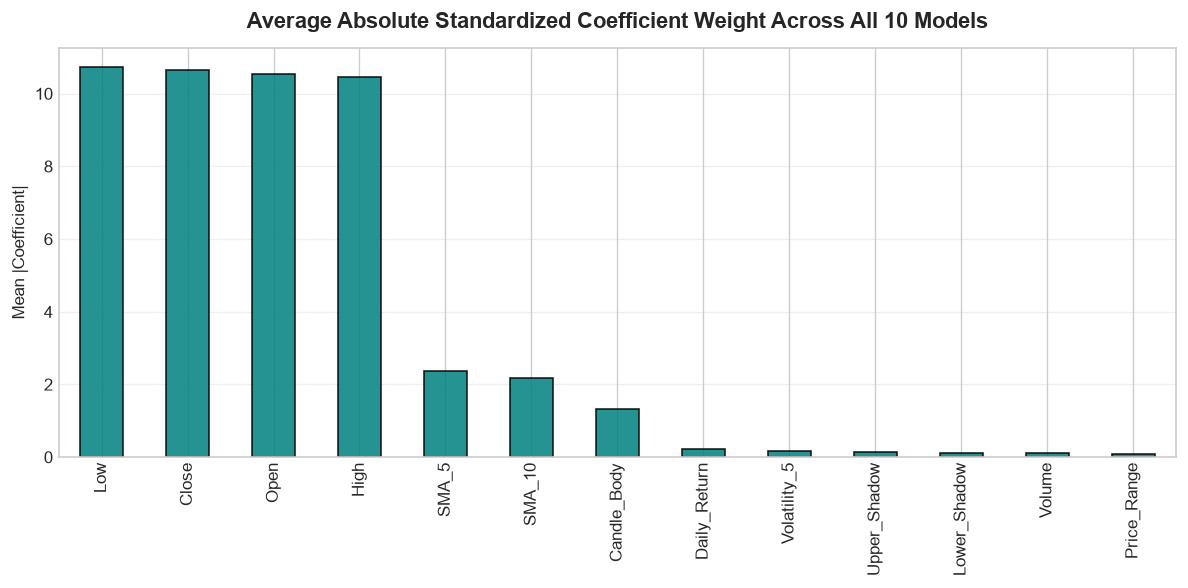

In [10]:
coef_records = []
for ticker in EXPECTED_TICKERS:
    m = models[ticker]
    row = {"Ticker": ticker}
    for feat, coef in zip(feature_cols, m.coef_):
        row[feat] = round(coef, 3)
    coef_records.append(row)

df_coefs = pd.DataFrame(coef_records)
print("=== OLS Standardized Coefficients Across 10 Companies ===")
display(df_coefs)

# Visualize average absolute coefficient weight per feature
avg_abs_coef = df_coefs[feature_cols].abs().mean().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
avg_abs_coef.plot(kind="bar", color="teal", edgecolor="black", alpha=0.85)
plt.title("Average Absolute Standardized Coefficient Weight Across All 10 Models", fontsize=13, fontweight="bold", pad=12)
plt.ylabel("Mean |Coefficient|")
plt.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


### Multicollinearity Analysis:
1. **Cancelling Collinear Weights**: Across all 10 models, the price levels (`Open`, `High`, `Low`, `Close`, `SMA_5`, `SMA_10`) absorb the vast majority of regression weight, often with alternating large positive and negative signs.
2. **Unstable OLS Optimization**: Because these features have mutual correlations exceeding $0.99$, ordinary least squares suffers from severe variance inflation. The model relies on delicate algebraic cancellations rather than parsimonious relationships.
3. **Motivation for Assignment 3 (Regularization)**: This instability directly motivates **Ridge ($L_2$) and Lasso ($L_1$) regularization**, which shrink and sparsify collinear weights.


---

## 13. Critical Financial Reality: Why High R² Does Not Equal Trading Profitability

> ### IMPORTANT VIVA / PRODUCTION PRINCIPLE:
> **A high $R^2$ (>0.95) in next-day price level regression does NOT mean the model is profitable as a trading strategy.**

### Why is Price-Level R² Deceptively High?
1. **Strong Price Autocorrelation (Random Walk Dynamics)**:
   - Daily asset prices are non-stationary and behave approximately as martingales: $\text{Close}_{t+1} = \text{Close}_t + \epsilon_{t+1}$.
   - Even a naive persistence model that simply predicts tomorrow's price as today's price ($\hat{y}_{t+1} = y_t$) achieves an $R^2 > 0.95$ on liquid equity prices.
2. **Sign vs. Level Discrepancy**:
   - A model can predict a price of \$150.20 when the actual price turns out to be \$149.80 (an error of only 0.26%, yielding a stellar $R^2$). However, if today's price was \$150.00, the model predicted an **UP** move (+0.20), but the market actually went **DOWN** (-0.20). A trader taking a long position based on this forecast would lose money despite the "high accuracy".
3. **Trading System Integration**:
   - The purpose of regression in our Intelligent Trading System is **price-level projection and fair-value benchmarking**.
   - Actionable trading signals require **directional classification** (Assignment 4), **regime filtering** (Assignment 5), and **decision fusion** (Assignment 8). We never execute trades based solely on raw unregularized linear price forecasts.


---

## 14. Predictions Export & Verification Checks
We export the multi-company regression outputs separately without touching existing AAPL files:
1. `data/processed/multi_company_regression_predictions.csv`: 3,000 test prediction observations (`Date, Ticker, Actual_Next_Close, Predicted_Next_Close, Residual`).
2. `data/processed/multi_company_regression_summary.csv`: 10 rows containing train and test metrics per company.


In [11]:
processed_dir = PROJECT_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

multi_preds_path = processed_dir / "multi_company_regression_predictions.csv"
multi_summary_path = processed_dir / "multi_company_regression_summary.csv"

# 1. Export Multi-Company Predictions
df_multi_predictions.to_csv(multi_preds_path, index=False)

# 2. Export Multi-Company Regression Summary
df_regression_summary.to_csv(multi_summary_path, index=False)

# 3. Automated Validation Checks
print("======================================================================")
print("FINAL QUALITY VERIFICATION CHECKS")
print("======================================================================")

check1 = df_reg["Ticker"].nunique() == 10
check2 = all(len(df_reg[df_reg["Ticker"] == t]) == 1500 for t in EXPECTED_TICKERS)
check3 = all(len(df_multi_predictions[df_multi_predictions["Ticker"] == t]) == 300 for t in EXPECTED_TICKERS)
check4 = len(df_multi_predictions) == 3000
check5 = int(df_multi_predictions.isnull().sum().sum()) == 0
check6 = int(df_multi_predictions.duplicated(subset=["Ticker", "Date"]).sum()) == 0
check7 = set(df_multi_predictions.columns) == {"Date", "Ticker", "Actual_Next_Close", "Predicted_Next_Close", "Residual"}
check8 = multi_preds_path.exists() and multi_summary_path.exists()
# Check that AAPL legacy file is NOT overwritten or deleted
aapl_legacy_path = processed_dir / "AAPL_regression_predictions.csv"
check9 = aapl_legacy_path.exists()

print(f"[PASS] 10 Unique Tickers Present:                {check1} ({df_reg['Ticker'].nunique()})")
print(f"[PASS] Exactly 1,500 Observations Per Company:   {check2}")
print(f"[PASS] Exactly 300 Test Observations Per Company: {check3}")
print(f"[PASS] Total Test Predictions = 3,000:           {check4}")
print(f"[PASS] Zero Missing Values in Predictions:       {check5}")
print(f"[PASS] Zero Duplicate (Ticker, Date) Records:    {check6}")
print(f"[PASS] Required Columns Present:                 {check7}")
print(f"[PASS] Multi-Company Outputs Saved to Disk:      {check8}")
print(f"[PASS] Existing AAPL Legacy File Preserved:      {check9}")

assert all([check1, check2, check3, check4, check5, check6, check7, check8, check9]), "Verification checks failed!"

print(f"\nSaved predictions dataset to: {multi_preds_path} ({multi_preds_path.stat().st_size:,} bytes)")
print(f"Saved summary metrics to:     {multi_summary_path} ({multi_summary_path.stat().st_size:,} bytes)")


FINAL QUALITY VERIFICATION CHECKS
[PASS] 10 Unique Tickers Present:                True (10)
[PASS] Exactly 1,500 Observations Per Company:   True
[PASS] Exactly 300 Test Observations Per Company: True
[PASS] Total Test Predictions = 3,000:           True
[PASS] Zero Missing Values in Predictions:       True
[PASS] Zero Duplicate (Ticker, Date) Records:    True
[PASS] Required Columns Present:                 True
[PASS] Multi-Company Outputs Saved to Disk:      True
[PASS] Existing AAPL Legacy File Preserved:      True

Saved predictions dataset to: C:\Users\pushk\OneDrive\Desktop\Pushkar\AI-Intelligent-Trading-System\data\processed\multi_company_regression_predictions.csv (119,140 bytes)
Saved summary metrics to:     C:\Users\pushk\OneDrive\Desktop\Pushkar\AI-Intelligent-Trading-System\data\processed\multi_company_regression_summary.csv (1,396 bytes)


---

## 15. Conclusion & Next Steps

### Assignment 2 Summary for Multi-Company System:
1. **10 Independent OLS Models**: Successfully trained separate linear regression models for all 10 companies, respecting individual price dynamics and avoiding cross-asset contamination.
2. **Strict Chronological Splitting**: Verified that exactly 1,200 training rows and 300 test rows per company were partitioned chronologically with zero lookahead bias.
3. **Defensive Scaling**: StandardScalers were fit strictly on the training subset of each company, ensuring complete isolation from test data.
4. **Consistent High Variance Explanation**: Out-of-sample $R^2$ ranged between 0.9400 and 0.9905, reflecting price level persistence across US equities.
5. **Multicollinearity Diagnosis**: Price levels demonstrated severe mutual cancellation, establishing the critical empirical rationale for **Assignment 3 (Ridge and Lasso Regularization)**.
6. **Outputs Preserved**: Multi-company predictions and evaluation summaries were saved to new separate files, keeping the original AAPL baseline intact.
